In [3]:
import equinox as eqx
import zodiax as zdx
import optax
import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
from backpac.systems.generic import MPLCSystem
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import zoom
from backpac.apply_complex_map import apply_complex_map

In [4]:
#Define MPLC parameters
diameter = 9e-3  # Aperture diameter
simulation_diameter = diameter * 2.0  # Simulation diameter
num_planes = 4  # Number of phase screens
total_length = 50.0e-2 # Initial total length of the system
center_wavel = 632e-9  # Center wavelength for the system
wavelengths = np.array([center_wavel])  # Wavelengths of the input modes

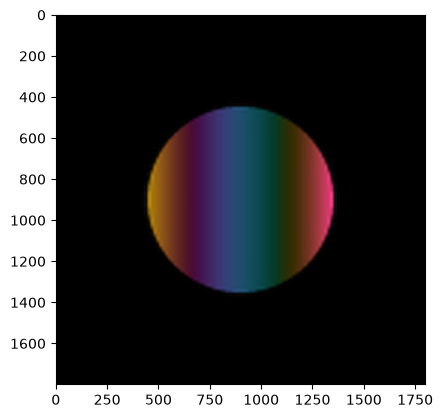

In [9]:
#Load input mode
input_mode = np.load('mplc_input_single_mode.npy')

#zero pad the input mode by factor of 2
input_mode = np.pad(input_mode, ((input_mode.shape[0]//2, input_mode.shape[0]//2), (input_mode.shape[1]//2, input_mode.shape[1]//2)), mode='constant')

lc_pix_size = 20e-6  # Liquid crystal pixel size
simulation_pix_size = lc_pix_size / 2.0  # Simulation pixel size
wf_npixels = round(simulation_diameter / simulation_pix_size)  # Number of pixels in the simulation

#normalize input mode
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

#interpolate input mode to match wf_npixels using zoom
input_mode = zoom(input_mode, (wf_npixels / input_mode.shape[0], wf_npixels / input_mode.shape[1]), order=3)

plt.figure()
plt.imshow(apply_complex_map(input_mode))

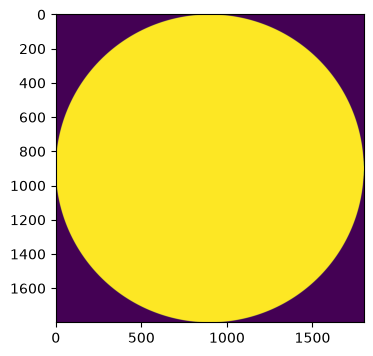

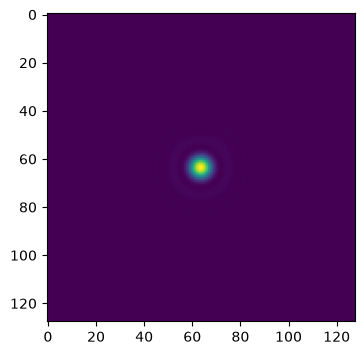

In [18]:
#Calculate output mode
focal_length = 50.0e-2  # Effective focal length for spot generation

# Generate output modes by propagating a circular aperture
wf_npix = input_mode.shape[0]  # Number of pixels in the wavefront
circ_aper = dlu.circular_aperture(npixels=wf_npix, diameter = diameter, oversample=5)
circ_aper = circ_aper / np.sqrt(np.sum(np.abs(circ_aper)**2))  # Normalize the circular aperture
circ_aperture = dl.TransmissiveLayer(circ_aper, normalise=True)

# Define the propagator for generating the output modes (Pupil -> Focal)
psf_npix = 128
#psf_pixel_scale = 20 * focal_length * center_wavel / diameter / psf_npix  # Pixel scale in the PSF plane
psf_pixel_scale = diameter / wf_npix  # Pixel scale in the PSF plane
to_focal = dl.MFTPropagator(
    [
        ("ThinLens", dl.ABCDConjugatePlane(focal_length)),  # Pupil -> Focal
    ],
    dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
)

# Define the optical layers for generating the output modes
layers_mode_gen = [
    ("aperture", circ_aperture),
    ("to_focal", to_focal),
]

# Construct the optics object for generating the output modes
optics_mode_gen = dl.LayeredOpticalSystem(
    wf_npixels=wf_npix,
    diameter=diameter,
    layers=layers_mode_gen,
)

psf = optics_mode_gen.propagate(center_wavel, return_wf=True)
output_mode = psf.phasor[0]

plt.figure(figsize=(15, 4))
plt.imshow(circ_aper)

plt.figure(figsize=(15, 4))
plt.imshow(np.abs(output_mode)**2)

In [19]:
mplc_system = MPLCSystem(
    input_modes = np.array([input_mode]),
    target_modes = np.array([output_mode]),
    diameter = diameter,
    array_diameter = simulation_diameter,
    bin_size = 2,
    num_planes = num_planes,
    total_length = total_length,
    target_coordspec_n = psf_npix,
    target_coordspec_d = psf_pixel_scale,

    wavelengths = wavelengths)

In [20]:
# #make 3 randomized initial phase screens
# key = jax.random.PRNGKey(0)
# initial_phase_screens = jax.random.uniform(key, (3, mplc_system.wf_npixels, mplc_system.wf_npixels)) * 2 * np.pi

#initialize the phase screens with zeros
initial_phase_screens = np.zeros((num_planes, mplc_system.wf_npixels, mplc_system.wf_npixels))

In [32]:
#Define wavefront matching loss function
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM(params, mplc_system):

    mplc_system = mplc_system.with_params(params)

    #propagate every input mode through the MPLC system
    res = mplc_system()

    #calculate the loss (summed over wavelengths and modes)
    #expand the target modes to match the shape of res
    target_modes_expanded = np.expand_dims(mplc_system.target_modes, axis=1)

    #calculate the overlap integral between the output modes and the target modes
    overlap = np.sum(np.conj(res) * target_modes_expanded, axis=(-2, -1))

    #calculate the loss as 1 - the mean of the squared magnitude of the overlap
    loss = 1 - np.mean(np.abs(overlap)**2)
    return loss


In [33]:
params = {
    "phase_screens": initial_phase_screens,
    "total_length": np.array(total_length),
}

optimizers = {
    "phase_screens": optax.adam(learning_rate=1e-2),
    "total_length": optax.adam(learning_rate=1e-3),
}
optim, opt_state = zdx.map_optimisers(params, optimizers)

#test the loss function
initial_loss, initial_grad = loss_fn_WFM(params, mplc_system)
print("Initial loss:", initial_loss)
print("Initial gradient norm:", optax.global_norm(initial_grad))

Initial loss: 0.9998357
Initial gradient norm: 0.005575898


In [34]:
# Run the optimisation loop
losses, params_out = [], []
num_iters = 1000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        loss, grads = loss_fn_WFM(params, mplc_system)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/1000 [00:00<?, ?it/s]

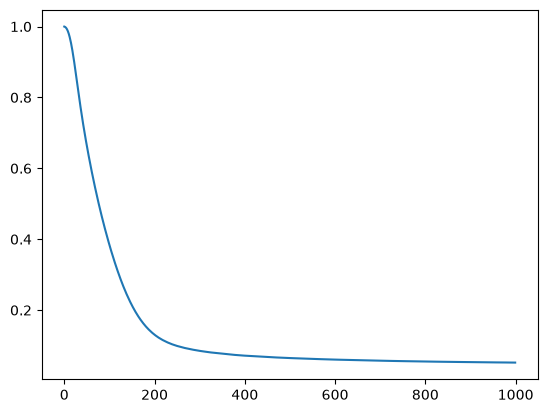

In [35]:
plt.figure()
plt.plot(losses)

0.498969


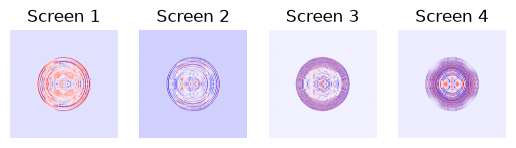

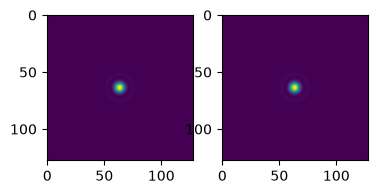

In [31]:
#plot the final phase screens
mplc_system_final = mplc_system.with_params(params)
filtered_phase_screens_final = mplc_system_final.mplc.phase_screens

np.save('filtered_phase_screens_final.npy', filtered_phase_screens_final)

plt.figure()
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(filtered_phase_screens_final[i], cmap='seismic')
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
res_final = mplc_system_final()

print(params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc_system.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)
